<a href="https://colab.research.google.com/github/fadouaElk/lab-clip-llava/blob/main/LAB_CLIP_LLaVA_Full_Lab_Statement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
CLIP (*Contrastive Language-Image Pre-training*, OpenAI 2021) is a model trained on about 400 million image–text pairs collected from the web. It learns to project images and texts into the **same embedding space**, so that an image and the sentence describing it end up close to each other. This allows comparing any image with any sentence without task-specific training.
CLIP relies on **natural language supervision**. Two approaches exist: predicting the exact caption of each image, or a **contrastive** objective that only has to recognize which caption goes with which image. The authors showed that exact caption prediction is much harder and slower to learn, whereas the contrastive objective is far more efficient, which is why CLIP adopts it (*OpenAI CLIP model explained* video).

**Q2.** What are its two main components?  
1. An **image encoder** (here a Vision Transformer ViT-B/32) that turns an image into a vector.
2. A **text encoder** (a Transformer) that turns a sentence into a vector.
Both outputs are linearly projected into a shared space and trained with a **contrastive loss**: matching image–text pairs are pulled together, non-matching pairs pushed apart.

**Q3.** What is the role of `CLIPProcessor`?  
It prepares the raw inputs for the model: it **tokenizes** the texts (token ids, attention mask, padding) and **pre-processes** the images (resizing to 224×224, center crop, normalization with the training mean/std, conversion to tensors).


**Q4.** What is the role of `CLIPModel`?

It contains the neural network itself (both encoders and projections). It computes the image and text embeddings and their similarity scores (`logits_per_image`, `logits_per_text`), i.e. the cosine similarities multiplied by a learned temperature.

In [7]:
# Run this cell first.
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [8]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?

The image size is (960, 1282): 960 pixels wide and 1282 pixels high

**Q6.** What type of data is stored in the PIL image object?

A PIL.Image.Image object stores a grid of pixels. In RGB mode, each pixel has 3 channels (Red, Green, Blue), each encoded as an integer from 0 to 255 (8 bits). Converted to a NumPy array, the image would have the shape (1282, 960, 3) with type uint8.

Image size: (960, 1282)
Image mode: RGB


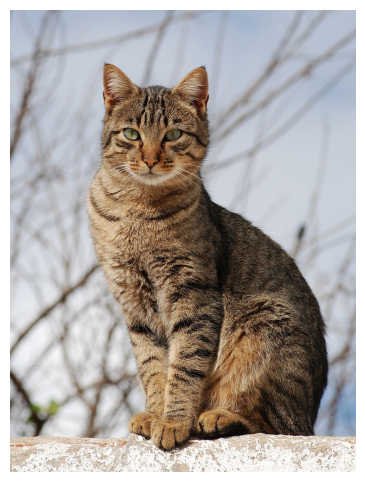

In [9]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.
IMAGE_PATH = "image.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  

The description "a photo of a cat" has the highest probability: 0.9939 (99.4 %). The other descriptions are far behind: "a photo of a person" 0.0031, "a photo of a dog" 0.0026, "a photo of a horse” 0.0003 and "a photo of a car" 0.0001.

**Q8.** Is it compatible with the actual image?

Yes. The image shows a tabby cat sitting outdoors, so CLIP's prediction is correct and very confident. The second-highest score goes to "a photo of a person” (0.0031) rather than "a photo of a dog" (0.0026), but these values are negligible: the model clearly separates the correct description from the others.

**Q9.** Why can CLIP compare an image with a sentence?  

Because CLIP has two encoders, one for images (a Vision Transformer) and one for texts (a Transformer), which project their inputs into the same vector space. They were trained together on about 400 million image–text pairs with a contrastive objective: matching image–caption pairs are pulled together, non-matching pairs are pushed apart. The similarity between an image and a sentence is then simply the cosine similarity of their vectors: the higher it is, the better the sentence describes the image.
Unlike one-hot encodings, which carry no notion of meaning, these dense embeddings place related concepts close to each other, and CLIP shares this space between images and texts.

**Q10.** What does `softmax()` do?

It converts the raw similarity scores (logits) into probabilities between 0 and 1 that sum to 1:

$$p_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

It amplifies the differences between scores, so the best description stands out clearly (here 0.9939 for "a photo of a cat"). These probabilities are relative to the list of candidates: they indicate which description is the best among those proposed, not whether it is true in absolute terms. Softmax is also at the heart of the attention mechanism, where it turns relevance scores into weights.

In [10]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9939
a photo of a dog                   : 0.0026
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0003
a photo of a person                : 0.0031


## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?

Zero-shot classification consists in classifying data into categories for which the model has never been explicitly trained, without any labeled example of these classes. With CLIP, each class name is turned into a sentence ("a photo of a {class}"), and the image is assigned to the class whose sentence is the most similar to it.

**Q12.** Why is it not necessary to train a new classifier?  

Because CLIP already learned, during pre-training on about 400 million image–text pairs, a general alignment between visual concepts and words. The class names, written as text, play the role of the classifier weights: the classifier is built on the fly from the text embeddings, so any new list of classes can be used immediately.
By contrast, the Embed => Encode => Attend => Predict classifier presented in the first video has to be trained on thousands of labeled documents. CLIP behaves like zero-shot prompting of an LLM: it relies only on its pre-trained knowledge and on the instruction (the class names).

**Q13.** What happens if the correct class is not included in the candidate classes?

CLIP still returns one of the proposed classes, the closest one, because softmax always distributes 100 % of the probability among the candidates. The prediction is necessarily wrong, and the probability can remain high, which gives a false impression of confidence.
In our test, with "cat" in the candidate list, CLIP correctly predicted "cat" with a probability of 0.9964. When "cat" was removed, CLIP predicted "dog" with a probability of 0.7188, although the image clearly shows a cat. The model chose the semantically closest class (another domestic animal), and the probability of 72 % does not reveal that the prediction is wrong.
Possible remedies: add an "other / unknown" class, or set a threshold on the raw similarity score rather than relying on the softmax probability.

In [11]:
# STUDENT TASK
def classify_image(image, classes, template="a photo of a {}"):
    """Zero-shot classification with CLIP. Returns (predicted_class, probability)."""
    prompts = [template.format(c) for c in classes]
    inputs = processor(text=prompts, images=image, return_tensors="pt", padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        probs = model(**inputs).logits_per_image.softmax(dim=1)[0].cpu()
    best = int(probs.argmax())
    return classes[best], float(probs[best])

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]


# Uncomment after implementing the function:
prediction, probability = classify_image(image, classes)
print("Prediction:", prediction)
print("Probability:", probability)

Prediction: cat
Probability: 0.996367335319519


In [12]:
classes_without_cat = ["dog", "car", "airplane", "horse", "bird"]
prediction, probability = classify_image(image, classes_without_cat)
print("Prediction:", prediction)
print("Probability:", probability)

Prediction: dog
Probability: 0.7188130021095276


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  

CLIP correctly classified 19 out of 20 images, i.e. an accuracy of 95 % ($Accuracy = \frac{19}{20} = 0.95$), with 6 classes (airplane, bird, cat, dog, football, horse). Most correct predictions have a very high probability (above 0.97), which shows that CLIP is confident on clear images.


**Q15.** Which images are incorrectly classified?  

Only one image is misclassified: cat6.jpeg, labeled "cat" but predicted as "dog" with a probability of 0.8107. This image actually contains both a kitten and a dog (a golden retriever): the dog is larger, centered and in the foreground, while the kitten is small and on the left side. The lower probability (0.81, versus more than 0.97 for most images) reflects this ambiguity.


**Q16.** Give at least two possible reasons for the errors.

Several objects in the same image (ambiguous label): cat6.jpeg contains a dog and a cat. CLIP produces a single global embedding for the whole image, which is dominated by the most visible object, here the dog. The ground-truth label "cat" is itself debatable: the prediction "dog" is not really wrong, it describes another object present in the image. Zero-shot classification with a single label is not suited to multi-object images.
Size and position of the object: the kitten occupies a much smaller part of the image than the dog, and CLIP center-crops the image to 224×224 pixels, which favors the central object (the dog) and may partially cut the kitten.
Close classes: cats and dogs are both domestic animals with similar contexts (here, the same field), which makes them easier to confuse than, for example, a cat and an airplane.
Prompt formulation and limited dataset: a generic template ("a photo of a {}") cannot express "a photo of a kitten next to a dog"; and with only 20 images, a single error changes the accuracy by 5 points.


Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [14]:
# STUDENT TASK
import os, re

IMAGE_DIR = "images"
VALID_EXT = (".jpg", ".jpeg", ".png", ".webp")

def label_from_filename(fname):
    """'cat12.jpg' -> 'cat'"""
    return re.match(r"[A-Za-z]+", os.path.splitext(fname)[0]).group(0).lower()

# Dataset in the required format: [("cat1.jpg", "cat"), ...]
dataset = [(f, label_from_filename(f)) for f in sorted(os.listdir(IMAGE_DIR))
           if f.lower().endswith(VALID_EXT)]
eval_classes = sorted({label for _, label in dataset})
print(len(dataset), "images — classes:", eval_classes)

rows = []
for fname, actual in dataset:
    img = Image.open(os.path.join(IMAGE_DIR, fname)).convert("RGB")
    pred, prob = classify_image(img, eval_classes)
    rows.append({"image": fname, "actual": actual, "predicted": pred,
                 "probability": round(prob, 4), "correct": pred == actual})

results = pd.DataFrame(rows)
accuracy = results["correct"].sum() / len(results)
display(results)
print(f"Accuracy = {results['correct'].sum()}/{len(results)} = {accuracy:.2%}")

print("\nMisclassified images:")
display(results[~results["correct"]])

20 images — classes: ['airplane', 'bird', 'cat', 'dog', 'football', 'horse']


,image,actual,predicted,probability,correct
0,airplane1.jpg,airplane,airplane,0.9962,True
1,airplane2.jpg,airplane,airplane,0.9968,True
2,bird1.jpeg,bird,bird,0.9930,True
3,bird2.jpg,bird,bird,0.9978,True
4,bird3.jpg,bird,bird,0.9976,True
5,cat1.jpg,cat,cat,0.9955,True
6,cat2.jpeg,cat,cat,0.9966,True
7,cat3.jpeg,cat,cat,0.9910,True
8,cat4.jpeg,cat,cat,0.9701,True
9,cat5.jpg,cat,cat,0.9915,True


Accuracy = 19/20 = 95.00%

Misclassified images:


,image,actual,predicted,probability,correct
10,cat6.jpeg,cat,dog,0.8107,False


## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  

No, the scores are not identical, although the five prompts describe the same image and have the same meaning. The cosine similarities range from 0.2739 for "a cat" to 0.3006 for “a photograph showing a cat”, and the CLIP logits from 27.39 to 30.06.
The differences look small in cosine similarity (about 0.027), but CLIP multiplies the similarity by a learned scale factor (×100), so the gap becomes 2.67 points in logits. In a softmax, such a gap means that one prompt would be about 14 times more probable than the other ($e^{2.67} \approx 14$), which can change the result of a classification.


**Q18.** Which prompt gives the highest score?  

The prompt "a photograph showing a cat" gives the highest score (cosine similarity 0.3006, logit 30.06), followed by "a photo of a cat" (0.2900) and "a domestic animal called a cat" (0.2887). The shortest prompt, “a cat”, gives the lowest score (0.2739).
Prompts that describe the image as a photograph score best because they are closest to the captions CLIP saw during training, which describe web images. The bare word “a cat” is less informative and less similar to these captions.


**Q19.** What does this demonstrate about prompt formulation?

It shows that CLIP is sensitive to the exact wording of the text: sentences with the same meaning produce different embeddings and therefore different scores. The best prompts are those closest to the captions seen during training, and adding context (here, specifying that it is a photograph) improves the match. This is why CLIP's authors use templates such as "a photo of a {}" rather than the bare class name, and prompt ensembling (averaging the embeddings of several templates), which improves zero-shot accuracy.
This is the same lesson as prompt engineering for LLMs, presented in the second video: a precise, well-formulated prompt gives better results than a vague one. The formulation of class descriptions is therefore a parameter to optimize, just like the model itself.

In [15]:
# STUDENT TASK
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

# Calculate and compare the scores for all prompts.
inputs = processor(text=prompts, images=image, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    out = model(**inputs)

# Cosine similarity between the image and each prompt
img_emb = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
txt_emb = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
cosine = (img_emb @ txt_emb.T)[0].cpu()

prompt_scores = pd.DataFrame({
    "prompt": prompts,
    "cosine_similarity": cosine.numpy().round(4),
    "clip_logit": out.logits_per_image[0].cpu().numpy().round(2),
}).sort_values("cosine_similarity", ascending=False)
display(prompt_scores)

,prompt,cosine_similarity,clip_logit
2,a photograph showing a cat,0.3006,30.059999
1,a photo of a cat,0.2900,29.000000
4,a domestic animal called a cat,0.2887,28.870001
3,an image containing a cat,0.2798,27.980000
0,a cat,0.2739,27.389999


# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  

The most similar image is football1.jpg, with a cosine similarity of 0.2676: it shows a football player in a stadium, about to kick the ball. It is followed by football3.jpeg (0.2588) and football2.jpeg (0.2575), which also show players with a ball on a pitch. The 4th and 5th results are dog3.jpeg (0.2043) and dog2.jpg (0.1972).


**Q21.** Is it semantically relevant?  

Yes. The top result, and more generally the three first results, are exactly the three football images of the database: they all show a person playing football, although no label or file name was used by the search. There is a clear gap of about 0.05 between the last football image (0.2575) and the first non-relevant image (0.2043), which shows that CLIP clearly separates relevant from non-relevant images.
The 4th and 5th results (two dogs) are not relevant: they appear only because the Top-5 must always return five images, and the database contains only three football images. Their presence can be explained by visual context: both dogs are photographed outdoors on grass or natural ground, a context close to a football pitch. This illustrates that a retrieval system always ranks all images, even when few are relevant, hence the interest of a similarity threshold (used in the mini-project) to keep only truly relevant results.


**Q22.** Why does this method not require image labels?  

The search relies only on the semantic proximity between embeddings: the text query and the images are projected by CLIP into the same vector space, and the images are ranked by their cosine similarity with the query. The content of each image is “described” by its embedding, computed directly from its pixels, so no manual annotation, keyword or category is needed.
Our experiment confirms it: the file names contain a class (football1.jpg…), but they are never used by the search, and the three football images were still ranked first.
It is the principle of vector databases presented in the second video: searching by meaning rather than by value (exact keywords, as in SQL). A query and an image can match without sharing any word or tag.


**Q23.** Give one real-world application of semantic image retrieval.

Searching a personal photo library in natural language, as in Google Photos or Apple Photos ("my dog at the beach", "birthday cake"), without having tagged the photos manually. Other examples: e-commerce search by description ("red dress with flowers"), searching press and media archives, sports video analysis (finding all the shots of a goal), content moderation, or retrieving medical images similar to a description.

20 images in the database
Embeddings shape: (20, 512)


,image,cosine_similarity
0,football1.jpg,0.2676
1,football3.jpeg,0.2588
2,football2.jpeg,0.2575
3,dog3.jpeg,0.2043
4,dog2.jpg,0.1972


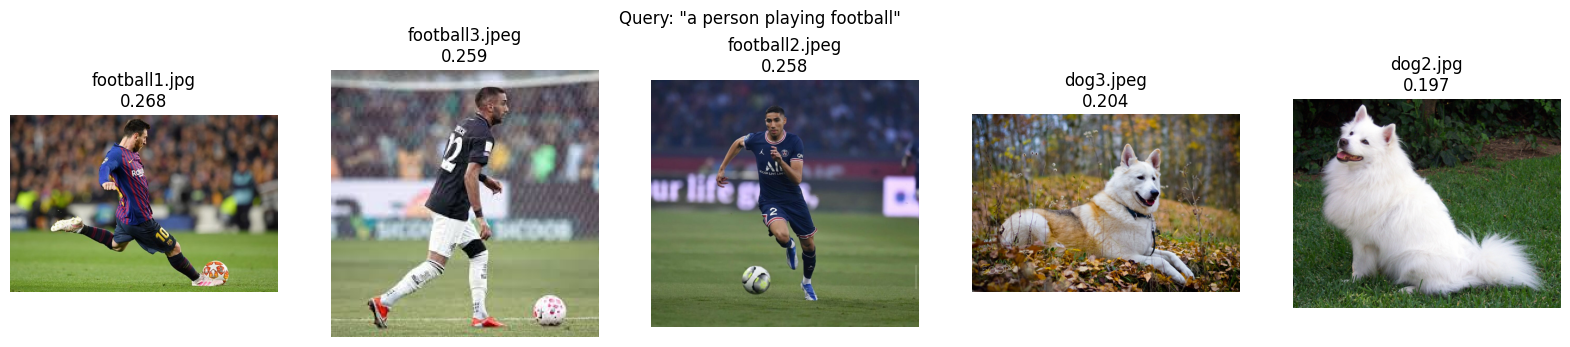

In [16]:
# STUDENT TASK
# 1. Put your images in IMAGE_DIR.
# 2. Compute image embeddings.
# 3. Compute the query embedding.
# 4. Calculate cosine similarity.
# 5. Display Top-5 images.

IMAGE_DIR = "images"
QUERY = "a person playing football"
VALID_EXT = (".jpg", ".jpeg", ".png", ".webp")

@torch.no_grad()
def clip_image_embeddings(images):
    """Normalized CLIP image embeddings (vision encoder + projection)."""
    pixel_values = processor(images=images, return_tensors="pt")["pixel_values"].to(device)
    pooled = model.vision_model(pixel_values=pixel_values).pooler_output
    emb = model.visual_projection(pooled)
    return emb / emb.norm(dim=-1, keepdim=True)

@torch.no_grad()
def clip_text_embeddings(texts):
    """Normalized CLIP text embeddings (text encoder + projection)."""
    tok = processor(text=texts, return_tensors="pt", padding=True)
    pooled = model.text_model(input_ids=tok["input_ids"].to(device),
                              attention_mask=tok["attention_mask"].to(device)).pooler_output
    emb = model.text_projection(pooled)
    return emb / emb.norm(dim=-1, keepdim=True)

# --- Exercise 7: image database with normalized CLIP embeddings ---
image_files = [f for f in sorted(os.listdir(IMAGE_DIR)) if f.lower().endswith(VALID_EXT)]
print(len(image_files), "images in the database")

imgs = [Image.open(os.path.join(IMAGE_DIR, f)).convert("RGB") for f in image_files]
image_embeddings = clip_image_embeddings(imgs)
torch.save({"files": image_files, "embeddings": image_embeddings.cpu()}, "clip_image_index.pt")
print("Embeddings shape:", tuple(image_embeddings.shape))

# --- Exercise 8: text-to-image retrieval ---
query_embedding = clip_text_embeddings([QUERY])
similarities = (query_embedding @ image_embeddings.T)[0].cpu()   # cosine similarity
top5 = similarities.topk(5)

top5_results = pd.DataFrame({
    "image": [image_files[i] for i in top5.indices],
    "cosine_similarity": top5.values.numpy().round(4),
})
display(top5_results)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, i, s in zip(axes, top5.indices, top5.values):
    ax.imshow(Image.open(os.path.join(IMAGE_DIR, image_files[i])))
    ax.set_title(f"{image_files[i]}\n{s:.3f}")
    ax.axis("off")
fig.suptitle(f'Query: "{QUERY}"')
plt.show()

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
Projection layer
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  

The vision encoder (a pre-trained CLIP ViT) extracts visual features from the image. It splits the image into patches and turns it into a sequence of vectors, one per image region, that describe its content (objects, colors, layout). In LLaVA, this encoder is reused from CLIP and is generally kept frozen: it brings the visual understanding learned by CLIP on 400 million image–text pairs.


**Q25.** Why is a projection layer required?  

The visual features produced by the vision encoder and the word embeddings of the language model do not live in the same space and do not have the same dimension (for example 1024 for CLIP ViT-L/14 versus 4096 for a 7B language model). The projection layer converts each visual feature into a "visual token" that the language model can read like a word token. It is the bridge between the two models.
The image thus becomes a sequence of visual tokens (576 for LLaVA 1.5, i.e. a 24×24 grid of patches) that occupy the language model’s context window, alongside the text tokens of the question. This layer is the first component trained in LLaVA, during the alignment stage.


**Q26.** What is the role of the language model?

The language model (Vicuna, based on LLaMA) receives the visual tokens followed by the user’s question, reasons over this sequence and generates the answer word by word. It brings language understanding, world knowledge and the ability to follow instructions and hold a conversation.

Training of LLaVA (How LLaVA works video):

Feature alignment: the vision encoder and the language model are frozen; only the projection layer is trained, on image–caption pairs, so that the visual tokens "speak the language" of the language model.
Visual instruction tuning: the projection and the language model are trained together on multimodal conversations (descriptions, questions, reasoning) generated with GPT-4. This step teaches the model to follow instructions about images.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [17]:
# STUDENT TASK
!pip install -q bitsandbytes accelerate
from transformers import AutoProcessor, LlavaForConditionalGeneration, BitsAndBytesConfig

# LLaVA 1.5 (7B) loaded in 4 bits (~5 GB of GPU memory, fits on a Colab T4).
# Lighter alternative if memory is insufficient: "llava-hf/llava-interleave-qwen-0.5b-hf"
MODEL_ID = "llava-hf/llava-1.5-7b-hf"

bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto"
)

@torch.no_grad()
def ask_llava(image, questions, max_new_tokens=200):
    """Conversation with LLaVA about one image. Returns the list of answers."""
    if isinstance(questions, str):
        questions = [questions]
    conversation, answers = [], []
    for i, q in enumerate(questions):
        content = ([{"type": "image"}] if i == 0 else []) + [{"type": "text", "text": q}]
        conversation.append({"role": "user", "content": content})
        prompt = processor_llava.apply_chat_template(conversation, add_generation_prompt=True)
        inputs = processor_llava(images=image, text=prompt, return_tensors="pt").to(llava.device, torch.float16)
        out = llava.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        answer = processor_llava.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
        answers.append(answer)
        conversation.append({"role": "assistant", "content": [{"type": "text", "text": answer}]})
    return answers

print("LLaVA loaded on", llava.device)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 21.2 MB/s eta 0:00:00


processor_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/674 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/505 [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

LLaVA loaded on cuda:0


In [18]:
import os, shutil
os.chdir("/content")
os.makedirs("images", exist_ok=True)
classes = ("airplane", "bird", "cat", "dog", "football", "horse")
for f in os.listdir("/"):
    if os.path.isfile("/" + f) and f.lower().startswith(classes) and f.lower().endswith((".jpg", ".jpeg", ".png")):
        shutil.move("/" + f, os.path.join("images", f))
print(len(os.listdir("images")), "images:", sorted(os.listdir("images")))

20 images: ['airplane1.jpg', 'airplane2.jpg', 'bird1.jpeg', 'bird2.jpg', 'bird3.jpg', 'cat1.jpg', 'cat2.jpeg', 'cat3.jpeg', 'cat4.jpeg', 'cat5.jpg', 'cat6.jpeg', 'dog1.jpg', 'dog2.jpg', 'dog3.jpeg', 'dog4.jpg', 'football1.jpg', 'football2.jpeg', 'football3.jpeg', 'horse1.jpg', 'horse2.jpg']


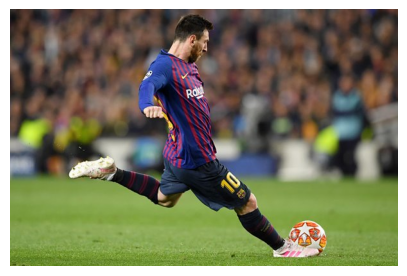

Q: What is happening in this image?
A: In this image, a soccer player is kicking a soccer ball on a field. The player is wearing a blue shirt and is in the process of kicking the ball.

Q: How many people are visible?
A: There are many people visible in the image, as they are watching the soccer player kick the ball.

Q: What objects can you identify?
A: In the image, you can identify a soccer player wearing a blue shirt and kicking a soccer ball. The player is actively engaged in the game, and the soccer ball is located near the player's feet. The scene captures the excitement and energy of the sport, as the player demonstrates their skills and athleticism.

Q: Describe the image in detail.
A: The image captures a soccer player in action, kicking a soccer ball on a field. The player is wearing a blue shirt and is focused on the ball, which is located near the bottom right corner of the image.

There are several other people in the scene, likely teammates or opponents, scattered around

In [19]:
llava_image = Image.open("images/football1.jpg").convert("RGB")
plt.figure(figsize=(5, 5)); plt.imshow(llava_image); plt.axis("off"); plt.show()

for q in ["What is happening in this image?", "How many people are visible?",
          "What objects can you identify?", "Describe the image in detail."]:
    print(f"Q: {q}\nA: {ask_llava(llava_image, q)[0]}\n")

## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

In [20]:
vqa_images = ["football1.jpg", "football2.jpeg", "football3.jpeg", "cat1.jpg", "dog1.jpg"]
vqa_questions = ["How many people are visible?", "What objects can you see?",
                 "Where are the people?", "What are they doing?", "What is visible on the board?"]

vqa_rows = []
for f in vqa_images:
    img = Image.open(os.path.join("images", f)).convert("RGB")
    for q in vqa_questions:
        a = ask_llava(img, q + " Answer briefly.", max_new_tokens=60)[0]
        vqa_rows.append({"Image": f, "Question": q, "LLaVA Answer": a, "Human Evaluation": None})
vqa = pd.DataFrame(vqa_rows)
pd.set_option("display.max_colwidth", 200)
display(vqa)

,Image,Question,LLaVA Answer,Human Evaluation
0,football1.jpg,How many people are visible?,1,None
1,football1.jpg,What objects can you see?,Soccer ball and soccer player,None
2,football1.jpg,Where are the people?,Stadium,None
3,football1.jpg,What are they doing?,Playing soccer,None
4,football1.jpg,What is visible on the board?,Soccer ball,None
5,football2.jpeg,How many people are visible?,1,None
6,football2.jpeg,What objects can you see?,Soccer ball and player,None
7,football2.jpeg,Where are the people?,Stadium,None
8,football2.jpeg,What are they doing?,Playing soccer,None
9,football2.jpeg,What is visible on the board?,Soccer ball,None


In [21]:
# 1 = correct, 0 = wrong (human evaluation of each LLaVA answer)
human_evaluation = [
    1, 1, 1, 1, 0,   # football1
    1, 1, 1, 1, 0,   # football2
    1, 1, 1, 1, 0,   # football3
    1, 1, 1, 1, 0,   # cat1
    1, 0, 0, 1, 0,   # dog1
]
vqa["Human Evaluation"] = ["Correct" if v else "Wrong" for v in human_evaluation]
vqa_accuracy = sum(human_evaluation) / len(human_evaluation)
display(vqa)
print(f"VQA accuracy = {sum(human_evaluation)}/{len(vqa)} = {vqa_accuracy:.2%}")
print(vqa.assign(ok=human_evaluation).groupby("Question")["ok"].mean())
vqa.to_csv("vqa_results.csv", index=False)

,Image,Question,LLaVA Answer,Human Evaluation
0,football1.jpg,How many people are visible?,1,Correct
1,football1.jpg,What objects can you see?,Soccer ball and soccer player,Correct
2,football1.jpg,Where are the people?,Stadium,Correct
3,football1.jpg,What are they doing?,Playing soccer,Correct
4,football1.jpg,What is visible on the board?,Soccer ball,Wrong
5,football2.jpeg,How many people are visible?,1,Correct
6,football2.jpeg,What objects can you see?,Soccer ball and player,Correct
7,football2.jpeg,Where are the people?,Stadium,Correct
8,football2.jpeg,What are they doing?,Playing soccer,Correct
9,football2.jpeg,What is visible on the board?,Soccer ball,Wrong


VQA accuracy = 18/25 = 72.00%
Question
How many people are visible?     1.0
What are they doing?             1.0
What is visible on the board?    0.0
What objects can you see?        0.8
Where are the people?            0.8
Name: ok, dtype: float64


**Q27. What is the VQA accuracy?**


LLaVA answered **18 questions correctly out of 25**, i.e. a VQA accuracy of **72 %** ($Accuracy = \frac{18}{25} = 0.72$). Per question type: counting 100 %, actions 100 %, objects 80 %, location of people 80 %, and "What is visible on the board?" 0 %.

**Q28. Which types of questions are difficult for LLaVA?**

- **Questions with a false premise:** "What is visible on the board?" was answered wrongly for all five images, since none of them contains a board. Instead of saying that there is no board, LLaVA always named an object of the image ("Soccer ball", "Cat", "Clock"). The model tends to comply with the question rather than contradict it.
- **Questions about absent objects or people:** for dog1.jpg, LLaVA first answered that 0 people are visible, then located the people "behind the dog", which is contradictory. It also mentioned a clock that does not appear in the image (hallucination).
- **Counting** is correct here because the images contain only one person or none; in the more complex scene of Exercise 10, LLaVA only answered "many people", without giving an accurate number.
- Simple perception questions (main object, action, place) are well handled.

## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  

No. The image (cat1.jpg) shows a tabby cat lying down, with a blurred background; there is no bicycle anywhere in the image.


**Q30.** Did LLaVA invent information?  

Yes. To the first question, LLaVA correctly answered: "No, there is no bicycle in this image". But when asked the leading follow-up questions in the same conversation, it contradicted itself and invented details: "The bicycle is blue" and "The bicycle is located in the background of the image". The model described a non-existent object with a color and a position, fluently and confidently.
LLaVA also added a smaller error in its first answer: it describes the cat as "sitting on a window sill", whereas the cat is lying down and no window sill is clearly visible. This shows that the model tends to complete the scene with plausible but unverified details. The leading questions ("What color…", "Where…") presuppose that the bicycle exists, and the model chooses to comply with the user rather than maintain its correct initial answer.

**Q31.** What is a visual hallucination?  

A visual hallucination is an answer in which the model describes objects, attributes or relations that are not present in the image, for example a non-existent bicycle, a wrong color or an invented number of people, while expressing it fluently and confidently. The answer sounds plausible, but it is not grounded in the visual content.


**Q32.** Why can a multimodal model hallucinate?

The language model is trained to produce plausible text, not to verify facts: it can favor its language habits over what the image actually shows.
Leading questions presuppose the existence of the object ("What color is the bicycle?"), and the model tends to comply with the user rather than contradict them.
Statistical associations learned during training: objects that often appear together (a street and a bicycle, a football pitch and several players) can be “completed” even when they are absent, as in Exercise 10.
Limited visual perception: the image is reduced to a low resolution and compressed into a few hundred visual tokens, which loses small details.
Training data (often automatically generated descriptions) contains errors and few examples of answers such as “this object is not in the image”.

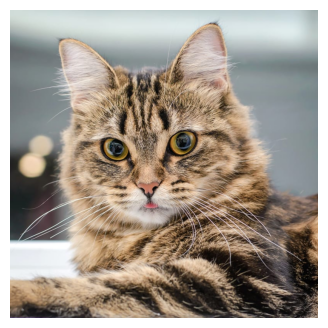

Q: Is there a bicycle in this image?
A: No, there is no bicycle in this image. The image features a cat sitting on a window sill.

Q: What color is the bicycle?
A: The bicycle is blue.

Q: Where is the bicycle located?
A: The bicycle is located in the background of the image.



In [22]:
no_bike_image = Image.open("images/cat1.jpg").convert("RGB")
plt.figure(figsize=(4, 4)); plt.imshow(no_bike_image); plt.axis("off"); plt.show()

qs = ["Is there a bicycle in this image?", "What color is the bicycle?", "Where is the bicycle located?"]
for q, a in zip(qs, ask_llava(no_bike_image, qs)):   # same conversation
    print(f"Q: {q}\nA: {a}\n")

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | Image + list of candidate texts | Image + free-form question |
| Main output | Similarity scores / embeddings | Generated text |
| Zero-shot classification | Yes, fast and calibrated | Possible through a question, slower |
| Image retrieval | Yes (shared embedding space) | Not suited |
| Text generation | No | Yes |
| VQA | No (only choice among given answers) | Yes |
| Open-ended response | No | Yes |

### Questions

**Q33.** Which model is better suited to image classification?  

**CLIP**: it directly gives a calibrated score for each class (0.9963 for "cat" here), is much lighter and faster, and scales to thousands of images (95 % accuracy in Exercise 5).



**Q34.** Which model is better for image description?  

**LLaVA**: it generates a free, rich description (objects, attributes, context), whereas CLIP can only choose among predefined sentences. The description must however be checked, since it may contain hallucinated details.



**Q35.** Which model is better for visual question answering?

**LLaVA**, which understands an arbitrary question and formulates an answer (72 % VQA accuracy in Exercise 11). CLIP can only rank answers given in advance.


**Q36.** Explain the fundamental difference between CLIP and LLaVA.

CLIP is a **discriminative / representation model**: it encodes images and texts into a shared space and measures their similarity, but it cannot generate text. LLaVA is a **generative model**: it uses a CLIP encoder to "see", a projection layer to turn visual features into tokens, and a language model to **generate** answers. CLIP answers *"which text matches this image?"*; LLaVA answers *"what can be said about this image?"*. They are complementary, and CLIP is actually a component of LLaVA.

In [24]:
animal_image = Image.open("images/cat1.jpg").convert("RGB")
texts = ["a photo of a cat", "a photo of a dog", "a photo of a horse"]
inputs = processor(text=texts, images=animal_image, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    p = model(**inputs).logits_per_image.softmax(dim=1)[0].cpu()
print("CLIP:")
for t, v in zip(texts, p):
    print(f"  {t:20s}: {v.item():.4f}")
print("\nLLaVA:\n", ask_llava(animal_image, "What animal is present in the image? Describe its appearance.")[0])


CLIP:
  a photo of a cat    : 0.9963
  a photo of a dog    : 0.0033
  a photo of a horse  : 0.0003

LLaVA:
 There is a cat present in the image. The cat has a striped pattern on its fur and is sitting on a window sill.


# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

In [25]:
def multimodal_assistant(image_path, question):
    """Image + Question -> Answer."""
    return ask_llava(Image.open(image_path).convert("RGB"), question)[0]

print("ASSISTANT:", multimodal_assistant("images/football2.jpeg",
      "What is the main subject of this image and what is he doing?"), "\n")

# BONUS — multimodal RAG agent: CLIP retrieval -> threshold routing -> LLaVA explanation
SIMILARITY_THRESHOLD = 0.24

def retrieve_and_explain(query, k=3, threshold=SIMILARITY_THRESHOLD):
    sims = (clip_text_embeddings([query]) @ image_embeddings.T)[0].cpu()
    top = sims.topk(k)
    results = [(image_files[i], float(s)) for s, i in zip(top.values, top.indices)]
    relevant = [(f, s) for f, s in results if s >= threshold]
    print(f'QUERY: "{query}"')
    if not relevant:                                   # routing: nothing relevant
        print(f"No image matches (best score {results[0][1]:.3f} < {threshold}).\n")
        return
    for f, s in relevant:                              # generation
        img = Image.open(os.path.join("images", f)).convert("RGB")
        expl = ask_llava(img, f'Does this image match "{query}"? Explain briefly.', max_new_tokens=60)[0]
        print(f"- {f} (CLIP {s:.3f}): {expl}")
    print()

retrieve_and_explain("a person playing football")
retrieve_and_explain("an astronaut floating in space")

ASSISTANT: The main subject of this image is a soccer player, who is actively running on the field while holding the ball. He is likely participating in a soccer match or practicing his skills. 

QUERY: "a person playing football"
- football1.jpg (CLIP 0.268): Yes, the image matches "a person playing football" as it shows a soccer player in action, kicking the ball on the field. The player is wearing a blue shirt and is in the process of kicking the ball, which is a common action during a soccer match.
- football3.jpeg (CLIP 0.259): Yes, the image matches "a person playing football" as it shows a man wearing a soccer uniform and standing on a soccer field, holding a soccer ball. The presence of the uniform and the soccer ball indicate that the man is actively participating in a soccer game
- football2.jpeg (CLIP 0.258): Yes, the image matches "a person playing football" as it shows a man running on a soccer field while holding a soccer ball. The man is actively engaged in the sport, wh